| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../9_METODOS_NUMERICOS_PARA_PDE/9_1_Finite_Difference_Method.ipynb) | [⏩](../9_METODOS_NUMERICOS_PARA_PDE/9_3_Finite_Volume_Method.ipynb) |

# 9.2 Finite Element Method: de la forma débil al ensamblaje

Los elementos finitos aproximan una solución en un espacio de funciones locales y formulan la ecuación mediante integrales. Este enfoque facilita geometrías complejas, mallas no uniformes y coeficientes variables. Construiremos FEM lineal 1D desde cero, con ensamblaje, cuadratura, Dirichlet y Neumann, y mediremos error de valores y derivadas.

Objetivos: entender funciones de prueba, integrar por partes, derivar una matriz de rigidez elemental, ensamblar un sistema disperso y reconocer por qué la forma débil exige menos regularidad que la PDE fuerte.

Este cuaderno se ejecuta de arriba abajo y genera todos los datos localmente. Los ejemplos son unidimensionales salvo un experimento 2D pequeño. Se necesitan cálculo multivariable, ecuaciones diferenciales y álgebra lineal. La sencillez de la geometría permite concentrarse en formulación, error, estabilidad y propiedades físicas.

## 1. El problema fuerte y sus fronteras

Tomamos
$$-(a(x)u'(x))'=f(x),\qquad x\in(0,1),\quad a(x)>0.$$
Con Dirichlet homogéneo, $u(0)=u(1)=0$. Si $a=1$, recuperamos Poisson 1D. La solución fuerte requiere derivadas suficientes para interpretar la ecuación punto a punto; con interfaces o datos menos suaves, una formulación integral resulta más natural.

El coeficiente $a$ puede representar conductividad o rigidez. La condición de positividad garantiza coercividad en el espacio con frontera fijada, bajo hipótesis apropiadas. Si $a$ se anula, cambia el tipo de problema y no deben suponerse las mismas garantías.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4),"axes.grid":True,"font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Derivar la forma débil

Multiplicamos por una función de prueba $v$ que vale cero en fronteras Dirichlet e integramos:
$$\int_0^1 -(a u')'v\,dx=\int_0^1fv\,dx.$$
Integrando por partes,
$$\int_0^1 a u'v'\,dx-[a u'v]_0^1=\int_0^1fv\,dx.$$
Para Dirichlet homogéneo el término de borde desaparece. Buscamos $u\in H_0^1$ tal que
$$\boxed{\int_0^1a u'v'\,dx=\int_0^1 f v\,dx\quad\forall v\in H_0^1}.$$
Ahora basta una primera derivada cuadrado-integrable. Si en la frontera derecha se prescribe $a u'(1)=g$, aparece un término $g v(1)$ en el lado derecho. Es una condición **natural** en la forma débil; Dirichlet se incorpora en el espacio de funciones admisibles.

## 3. Bases locales tipo sombrero

En nodos $x_0<\cdots<x_N$, cada función $\phi_i$ vale uno en $x_i$, cero en otros nodos y es lineal por tramos. Aproximamos $u_h=\sum_i U_i\phi_i$. En Galerkin usamos las mismas bases como pruebas.

Las funciones tienen soporte solo en elementos adyacentes. Por ello $K_{ij}=\int a\phi_i'\phi_j'$ es cero cuando las bases no se solapan. La localidad crea matrices dispersas y permite refinar regiones sin añadir grados de libertad en todo el dominio.

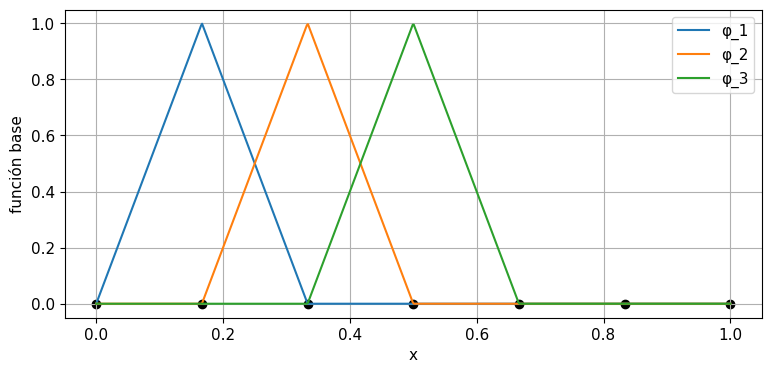

In [2]:
nodes=np.linspace(0,1,7); q=np.linspace(0,1,600)
for i in [1,2,3]:
    values=np.zeros_like(nodes); values[i]=1.
    plt.plot(q,np.interp(q,nodes,values),label=f"φ_{i}")
plt.scatter(nodes,np.zeros_like(nodes),color="black")
plt.xlabel("x"); plt.ylabel("función base"); plt.legend(); plt.show()

**Interpretación del experimento.** Cada sombrero afecta solo dos elementos. Sus derivadas son constantes por tramos y saltan en los nodos, pero siguen siendo cuadrado-integrables. La segunda derivada clásica no existe en todos los puntos, lo que justifica usar la formulación débil.

## 4. Matriz y carga de un elemento

En $e=[x_L,x_R]$, $h_e=x_R-x_L$, las bases locales son $N_1=(x_R-x)/h_e$ y $N_2=(x-x_L)/h_e$. Para $a$ constante,
$$K^e=\frac a{h_e}\begin{pmatrix}1&-1\\-1&1\end{pmatrix},\qquad
F_i^e=\int_e fN_i\,dx.$$
Con $a$ variable se integra $a(x)$ en la cuadratura. Usaremos Gauss de dos puntos, exacto para polinomios hasta grado tres. La carga de una fuente no polinómica es aproximada; aumentar orden de cuadratura permite separar error de integración y error del espacio FEM.

El cambio desde $[-1,1]$ al elemento aporta el jacobiano $h_e/2$. Las derivadas $N_i'$ tienen factores $1/h_e$, por lo que la rigidez termina escalando como $1/h_e$.

In [3]:
from numpy.polynomial.legendre import leggauss
def assemble(nodes,source,coefficient=lambda x:np.ones_like(x),quadrature=3):
    rows=[]; cols=[]; data=[]; load=np.zeros(len(nodes))
    xi,wi=leggauss(quadrature)
    for element in range(len(nodes)-1):
        left,right=nodes[element:element+2]; h=right-left
        x=(left+right)/2+h*xi/2; weights=h*wi/2
        basis=np.vstack([(1-xi)/2,(1+xi)/2]); gradients=np.array([-1/h,1/h])
        Ke=np.outer(gradients,gradients)*np.dot(weights,coefficient(x))
        Fe=basis@(weights*source(x))
        ids=[element,element+1]
        for local_i,global_i in enumerate(ids):
            load[global_i]+=Fe[local_i]
            for local_j,global_j in enumerate(ids):
                rows.append(global_i); cols.append(global_j); data.append(Ke[local_i,local_j])
    K=sparse.coo_matrix((data,(rows,cols)),shape=(len(nodes),len(nodes))).tocsr()
    return K,load

K,F=assemble(np.array([0.,0.25]),lambda x:np.ones_like(x),quadrature=2)
print("Rigidez de un elemento:",K.toarray())
print("Carga fuente constante:",F)

Rigidez de un elemento: [[ 4. -4.]
 [-4.  4.]]
Carga fuente constante: [0.125 0.125]


**Interpretación del experimento.** Para longitud 0.25 y a=1, la rigidez debe ser 4 veces la matriz mostrada y la carga vale $(0.125,0.125)$. Sumar ambas cargas da la integral de la fuente en ese elemento.

## 5. Ensamblaje global y Dirichlet

Las contribuciones de elementos que comparten un nodo se suman. Con índices libres $I$ y fijados $B$, el sistema es
$$K_{II}U_I=F_I-K_{IB}U_B.$$
Esta eliminación conserva simetría. Si se cambia solo una fila para imponer Dirichlet, la matriz resultante puede dejar de ser simétrica. Para fronteras no homogéneas, omitir $K_{IB}U_B$ produce una solución incorrecta aunque el sistema se resuelva sin errores.

Simetría max: 0.0
Residual libre: 7.549516567451064e-15


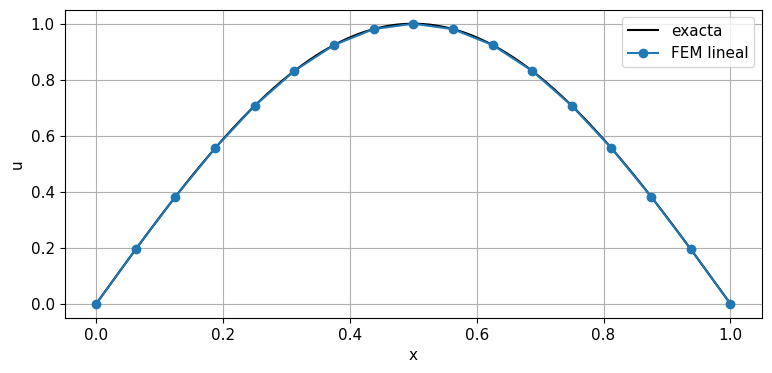

In [4]:
def solve_dirichlet(nodes,source,coefficient=lambda x:np.ones_like(x),left=0.,right=0.):
    K,F=assemble(nodes,source,coefficient)
    U=np.zeros(len(nodes)); fixed=np.array([0,len(nodes)-1]); U[fixed]=[left,right]
    free=np.arange(1,len(nodes)-1)
    rhs=F[free]-K[free][:,fixed]@U[fixed]
    U[free]=spsolve(K[free][:,free],rhs)
    return U,K,F

nodes=np.linspace(0,1,17)
U,K,F=solve_dirichlet(nodes,lambda x:np.pi**2*np.sin(np.pi*x))
q=np.linspace(0,1,1000)
plt.plot(q,np.sin(np.pi*q),"k",label="exacta")
plt.plot(nodes,U,"o-",label="FEM lineal")
plt.xlabel("x"); plt.ylabel("u"); plt.legend(); plt.show()
print("Simetría max:",np.max(abs((K-K.T).data),initial=0.))
print("Residual libre:",np.max(abs((K@U-F)[1:-1])))

**Interpretación del experimento.** Los segmentos representan realmente la función FEM entre nodos. En 1D y ciertos casos, valores nodales pueden resultar excepcionalmente precisos; para medir error del espacio hay que evaluar también entre nodos y en derivadas.

## 6. Error L² y error H¹

Para elementos lineales, bajo regularidad adecuada se espera $\|u-u_h\|_{L^2}=O(h^2)$ y $\|u'-u_h'\|_{L^2}=O(h)$. El segundo es la seminorma $H^1$ del error; la norma completa incluye también el término $L^2$.

Medimos ambos con cuadratura por elemento. No basta comparar valores nodales, porque el interpolante tiene forma lineal dentro de cada elemento.

Orden L2: [1.996357 1.99909  1.999772 1.999943]
Orden seminorma H1: [0.99722  0.999305 0.999826 0.999957]


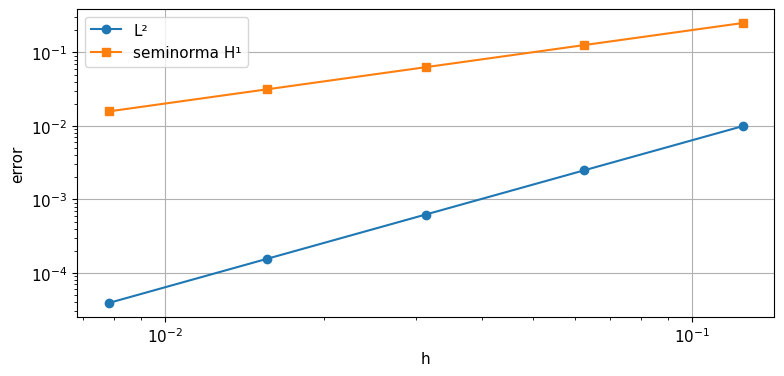

In [5]:
def errors_fem(nodes,U,exact,exact_gradient):
    xi,wi=leggauss(5); l2=0.; h1=0.
    for j in range(len(nodes)-1):
        h=nodes[j+1]-nodes[j]; x=(nodes[j]+nodes[j+1])/2+h*xi/2
        uh=U[j]*(1-xi)/2+U[j+1]*(1+xi)/2
        gradient=(U[j+1]-U[j])/h
        l2+=h/2*np.dot(wi,(uh-exact(x))**2)
        h1+=h/2*np.dot(wi,(gradient-exact_gradient(x))**2)
    return np.sqrt(l2),np.sqrt(h1)

ns=np.array([8,16,32,64,128]); e_l2=[]; e_h1=[]
for n in ns:
    nodes=np.linspace(0,1,n+1); U,_,_=solve_dirichlet(nodes,lambda x:np.pi**2*np.sin(np.pi*x))
    l2,h1=errors_fem(nodes,U,lambda x:np.sin(np.pi*x),lambda x:np.pi*np.cos(np.pi*x))
    e_l2.append(l2); e_h1.append(h1)
print("Orden L2:",np.log2(np.array(e_l2[:-1])/e_l2[1:]))
print("Orden seminorma H1:",np.log2(np.array(e_h1[:-1])/e_h1[1:]))
plt.loglog(1/ns,e_l2,"o-",label="L²")
plt.loglog(1/ns,e_h1,"s-",label="seminorma H¹")
plt.xlabel("h"); plt.ylabel("error"); plt.legend(); plt.show()

**Interpretación del experimento.** La tasa de valores es más alta que la de derivadas. Si una aplicación SciML necesita flujos o gradientes, medir solo error en valores puede exagerar la calidad del campo.

## 7. Coeficiente variable y solución fabricada

Para $a(x)=1+x$, elige $u_*(x)=x(1-x)$. Entonces $u_*'=1-2x$ y
$$f=-(a u_*')'=1+4x.$$
La solución satisface fronteras cero. Usamos una malla no uniforme para demostrar que el ensamblaje trabaja con longitud real de cada elemento. No se reutiliza un único paso global.

Errores L2/H1: (np.float64(0.00028147221551552866), np.float64(0.022357062557632208))


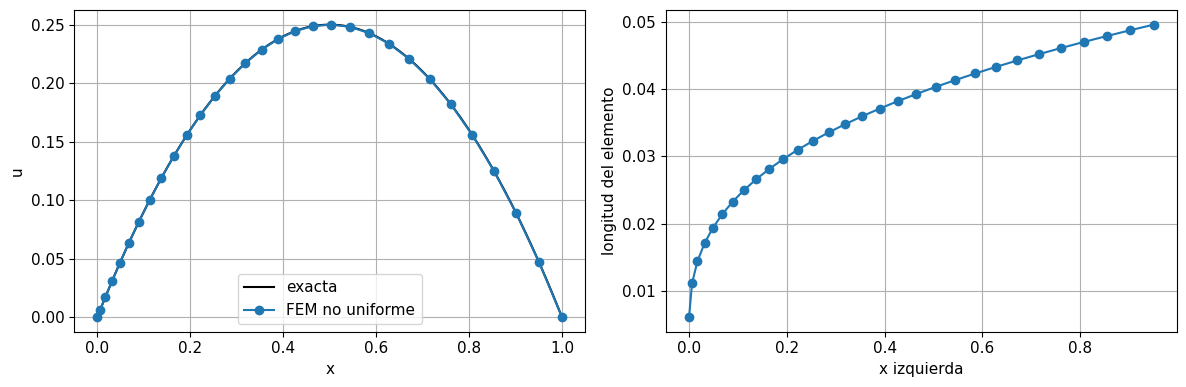

In [6]:
nodes=np.linspace(0,1,31)**1.5
U,K,F=solve_dirichlet(nodes,lambda x:1+4*x,lambda x:1+x)
q=np.linspace(0,1,600)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(q,q*(1-q),"k",label="exacta")
ax[0].plot(nodes,U,"o-",label="FEM no uniforme"); ax[0].legend()
ax[0].set(xlabel="x",ylabel="u")
ax[1].plot(nodes[:-1],np.diff(nodes),"o-"); ax[1].set(xlabel="x izquierda",ylabel="longitud del elemento")
plt.tight_layout(); plt.show()
print("Errores L2/H1:",errors_fem(nodes,U,lambda x:x*(1-x),lambda x:1-2*x))

**Interpretación del experimento.** La malla se concentra cerca de cero y el operador incorpora a(x) en su integral. Concentrar nodos donde no hace falta no garantiza eficiencia; una adaptación útil se guía por error y por observables.

## 8. Neumann como término natural

Resolvemos $-u''=2$, $u(0)=0$, $u'(1)=1$. La solución es $u=-x^2+3x$. La integración por partes añade $+1$ a la carga del nodo derecho, que ahora es libre.

El signo se deriva del término de frontera, no se memoriza sin convención. Si se prescribe flujo físico $q=-a u'$, el número dado tiene signo contrario a $a u'$ en ese extremo.

Valor derecho exacto/numérico: 2.0 1.999999999999992


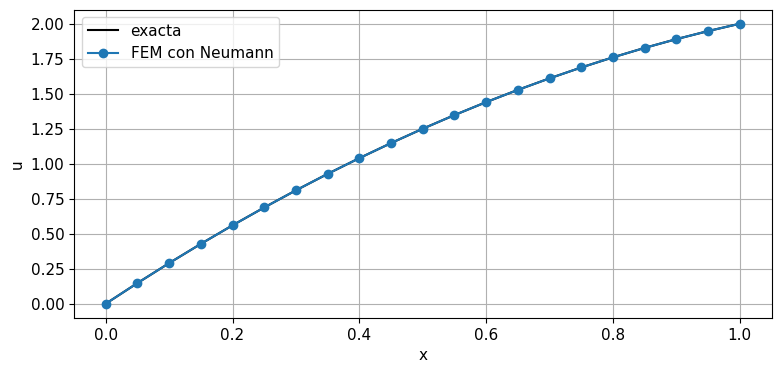

In [7]:
nodes=np.linspace(0,1,21); K,F=assemble(nodes,lambda x:2*np.ones_like(x))
F[-1]+=1.  # a*u'(1)=1
U=np.zeros(len(nodes)); free=np.arange(1,len(nodes))
U[free]=spsolve(K[free][:,free],F[free])
plt.plot(nodes,-nodes**2+3*nodes,"k",label="exacta")
plt.plot(nodes,U,"o-",label="FEM con Neumann")
plt.xlabel("x"); plt.ylabel("u"); plt.legend(); plt.show()
print("Valor derecho exacto/numérico:",2.,U[-1])

**Interpretación del experimento.** El nodo derecho no se fija por Dirichlet: se calcula a partir de la condición de derivada. En Neumann puro, sin ningún valor fijado, la constante de la solución quedaría libre y habría que imponer una referencia de promedio o potencial.

## 9. Interpretación energética

Para Dirichlet homogéneo, el funcional
$$\mathcal E(v)=\frac12\int a(v')^2dx-\int f v\,dx$$
tiene como condición de estacionariedad la forma débil. Restringirlo al espacio FEM produce $\mathcal E(U)=U^TKU/2-U^TF$ y gradiente $KU-F$.

Esto conecta FEM con optimización variacional y modelos basados en energía. Bajo positividad apropiada, el mínimo es único en el espacio admisible. Una red que minimiza una energía continua debe integrar correctamente y satisfacer fronteras; no basta usar una parametrización flexible sin controlar esas partes del problema.

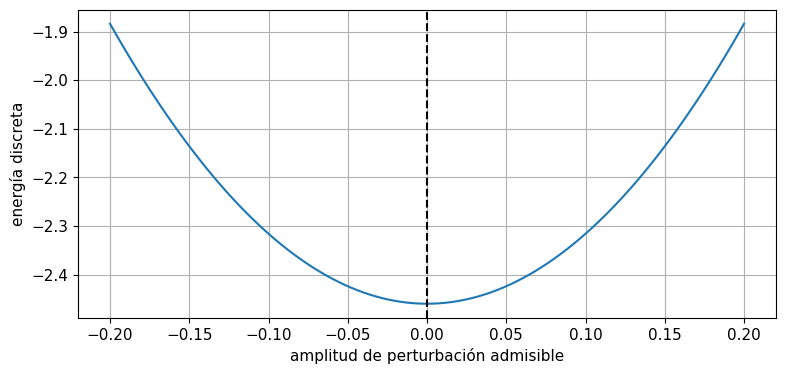

In [8]:
nodes=np.linspace(0,1,17); U,K,F=solve_dirichlet(nodes,lambda x:np.pi**2*np.sin(np.pi*x))
rng=np.random.default_rng(5); perturb=rng.normal(size=len(nodes)); perturb[[0,-1]]=0.
perturb/=np.linalg.norm(perturb)
energy=lambda V:0.5*V@(K@V)-V@F
amplitudes=np.linspace(-0.2,0.2,101)
energies=np.array([energy(U+a*perturb) for a in amplitudes])
plt.plot(amplitudes,energies); plt.axvline(0,color="k",linestyle="--")
plt.xlabel("amplitud de perturbación admisible"); plt.ylabel("energía discreta")
plt.show()

**Interpretación del experimento.** La energía mínima aparece en la solución ensamblada dentro de la dirección perturbada. Este control muestra una propiedad variacional del método, aunque no demuestra por sí solo precisión física o suficiencia de la malla.

## 10. Mallas, regularidad y orden

Elementos lineales son $C^0$, por lo que sus valores son continuos pero sus gradientes pueden saltar. Para un problema de segundo orden, la forma débil usa primeras derivadas y este espacio es suficiente. Para una PDE de cuarto orden puede requerirse mayor continuidad o una formulación mixta.

Refinamiento h reduce tamaños de elementos; refinamiento p aumenta su grado polinómico. Una solución suave puede aprovechar grados altos; singularidades locales suelen requerir malla adaptada. En geometrías 2D y 3D, calidad de elementos y representación de la frontera también afectan precisión y condicionamiento.

## 11. Cuadratura y comparación con otros métodos

FEM separa elección del espacio, formulación y cuadratura. Una cuadratura insuficiente puede cambiar matriz y estabilidad. Una malla fina no corrige automáticamente un error de ensamblaje ni una fuente mal derivada.

En 1D uniforme con coeficiente constante, FEM lineal y diferencias finitas pueden producir matrices relacionadas por un factor de escala; sus cargas representan información diferente, integral frente a punto a punto. FEM no garantiza conservación local por celda en toda formulación: para flujos exactos locales se usan métodos mixtos u otras variantes. Compara propiedades concretas en lugar de declarar un método superior por su nombre.

## 12. Verificación, validación y vínculo con SciML

Una **verificación** pregunta si resolvemos correctamente las ecuaciones que elegimos: compara soluciones exactas, realiza refinamiento de malla, mide residual y observa propiedades discretas. Una **validación física** compara el modelo con mediciones independientes y sus incertidumbres. Un método de elementos finitos puede estar perfectamente verificado y aun así representar una ley física inadecuada.

Para fabricar una solución conocida, elige $u_*$, sustitúyela en la PDE y deriva la fuente y las fronteras correspondientes. Al ejecutar el solver, compara con $u_*$ en una norma definida. Este método detecta signos, índices y condiciones de frontera mal implementados; no prueba por sí solo desempeño en todo problema.

Si los campos numéricos se usan para entrenar un operador neuronal, documenta malla, paso temporal, condiciones de frontera, precisión del solver y distribución de parámetros. Reserva casos de prueba y compara también resoluciones no vistas. Un modelo aprendido puede reproducir el sesgo de discretización de sus etiquetas; una métrica sobre la misma malla no revela necesariamente ese problema.

Una PINN utiliza residuales de una PDE, pero también necesita satisfacer datos iniciales y de frontera. Un residual pequeño en pocos puntos no garantiza un campo preciso entre ellos. Compara contra una solución numérica refinada, revisa balances y calcula una norma sobre una malla de evaluación independiente. Las distintas formulaciones de residual, fuerte e integral, aportan criterios científicos diferentes.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../9_METODOS_NUMERICOS_PARA_PDE/9_1_Finite_Difference_Method.ipynb) | [⏩](../9_METODOS_NUMERICOS_PARA_PDE/9_3_Finite_Volume_Method.ipynb) |